# Hybrid UI reconstruction from two RICO screens

Mix two **global RICO layout IDs**, decode their combined embedding with a matching trained projector + LoRA decoder, and visualize the **JSON-repaired** hybrid.

The example uses screens **6 + 19**, **Qwen2.5-1.5B**, and **4096_last**. Run all cells using the repository's Python environment. No encoder or training is needed. Model files must already be cached by default.

Two comparisons are displayed and exported:
1. Source A wireframe | Source B wireframe | Repaired hybrid wireframe.
2. Source A screenshot | Source B screenshot | Repaired hybrid wireframe.

This is an exploratory generation experiment: averaging embeddings does not guarantee a semantic union or a novel interface. There is no ground-truth hybrid, so reconstruction accuracy against either source would not measure hybrid quality.

## 1. Configuration

Edit this cell, then **Run All**. The decoder is cached when its checkpoint and device stay the same. `ALPHA = 0` selects A; `ALPHA = 1` selects B. `average` always uses equal weights; `weighted_average` uses `ALPHA`. For another operation, choose `custom` and edit `custom_operation` below.

possible tests: 

- 70538 music player
- 70494 gallery

1. 70629.jpg settings list
6. 70916.jpg registration page
7. 71089.jpg login

In [1]:
from pathlib import Path

SCREEN_A = 70538                         # Global layouts/6.json and embeddings/.../6.npz
SCREEN_B = 70494
MODEL_SLUG = "qwen2.5-1.5b"
EMBEDDINGS = "4096_last"               # Also e.g. "4096_avg", "4x4096_avg"

OPERATION = "weighted_average"        # "average", "weighted_average", or "custom"
ALPHA = 0.55                           # Weight of B for weighted_average
DEVICE = "auto"                      # "auto", "cpu", or e.g. "cuda:0"
MAX_NEW_TOKENS = 4096
LOCAL_FILES_ONLY = True              # False permits Hugging Face downloads
CPU_THREADS = 8                      # Avoid excessive CPU thread overhead

# Optional explicit paths. Relative paths are resolved from the repository root.
DATA_DIR_OVERRIDE = None             # Directory containing <global_id>.json and .jpg
EMBEDDINGS_DIR_OVERRIDE = None
ADAPTER_DIR_OVERRIDE = None          # Contains best_projector.pth and best_lora_adapter/
BASE_MODEL_OVERRIDE = None           # Local LM directory for the SAME base model
LEGACY_PREFIX_TOKENS = 128           # Old single-vector checkpoints without prefix_pos

SHOW_LABELS = True
HYBRID_ASPECT = "source_a"            # "source_a", "source_b", or height/width, e.g. 16/9
FIGURE_WIDTH_CM = 24
FIGURE_HEIGHT_CM = 12
EXPORT = True
OUTPUT_DIR = "graphics/hybrid_ui_reconstruction"  # Separate from benchmark reconstructions

## 2. Load the two sources

IDs refer directly to filenames, never DataFrame row positions or per-trace gesture IDs. Ground truths use the canonical cleaner unchanged. A model/embedding combination needs its own matching trained adapter; selecting a model name does not train one.

In [2]:
import gc
import importlib
import json
import math
import sys
import textwrap
import time
from datetime import datetime, timezone

import json_repair
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import Markdown, display
from matplotlib.patches import Patch, Rectangle
from PIL import Image
from peft import PeftModel
from transformers import AutoConfig, AutoModelForCausalLM, AutoTokenizer

ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents)
             if (p / "2_train_adapter.py").is_file()), None)
if ROOT is None:
    raise FileNotFoundError("Open the notebook within the screen2vec-revisited repository.")
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from utils import clean_screen, device_frame
from reconstruction_metrics import flatten_components

# Import training primitives directly: 3_json_reconstruction.py pins a specific GPU.
adapter_module = importlib.import_module("2_train_adapter")

def repo_path(value):
    path = Path(value).expanduser()
    return path if path.is_absolute() else ROOT / path

embedding_name = EMBEDDINGS.removeprefix("embeddings_")
embedding_dir = (repo_path(EMBEDDINGS_DIR_OVERRIDE) if EMBEDDINGS_DIR_OVERRIDE else
                 ROOT / f"embeddings_{embedding_name}")
adapter_dir = (repo_path(ADAPTER_DIR_OVERRIDE) if ADAPTER_DIR_OVERRIDE else
               ROOT / f"adapter_model_out_embeddings_{embedding_name}_full_{MODEL_SLUG}")
projector_path = adapter_dir / "best_projector.pth"
lora_dir = adapter_dir / "best_lora_adapter"
data_dirs = ([repo_path(DATA_DIR_OVERRIDE)] if DATA_DIR_OVERRIDE else
             [ROOT.parent / "rico-data/data/layouts", ROOT / "data/rico-examples",
              ROOT / "rico/examples"])
if not projector_path.is_file() or not (lora_dir / "adapter_config.json").is_file():
    available = "\n".join(sorted(p.name for p in ROOT.glob("adapter_model_out_*") if p.is_dir()))
    raise FileNotFoundError(
        f"Missing matched best_projector.pth / best_lora_adapter in {adapter_dir}.\n"
        f"Available adapter directories:\n{available}\n"
        "Choose an existing pair or set ADAPTER_DIR_OVERRIDE."
    )

def load_source(screen_id):
    if isinstance(screen_id, bool) or not isinstance(screen_id, int) or screen_id < 0:
        raise ValueError("Screen IDs must be nonnegative global RICO integers.")
    embedding_path = embedding_dir / f"{screen_id}.npz"
    json_path = next((d / f"{screen_id}.json" for d in data_dirs
                      if (d / f"{screen_id}.json").is_file()), None)
    if not embedding_path.is_file() or json_path is None:
        raise FileNotFoundError(f"Missing embedding or layout for global RICO ID {screen_id}: "
                                f"{embedding_path}; searched {data_dirs}")
    screenshot_path = json_path.with_suffix(".jpg")
    if not screenshot_path.is_file():
        raise FileNotFoundError(f"Missing screenshot: {screenshot_path}")
    with np.load(embedding_path, allow_pickle=False) as archive:
        embedding = archive["embedding"].astype(np.float32)
    if embedding.ndim not in (1, 2) or embedding.size == 0 or not np.isfinite(embedding).all():
        raise ValueError(f"{embedding_path}: expected finite (D,) or (N, D) embedding.")
    raw = json.loads(json_path.read_text(encoding="utf-8"))
    width, height = device_frame(raw["activity"]["root"])
    if width <= 0 or height <= 0:
        raise ValueError(f"Invalid device frame for screen {screen_id}.")
    with Image.open(screenshot_path) as screenshot:
        screenshot = screenshot.convert("RGB").copy()
    return dict(id=screen_id, embedding=embedding, embedding_path=embedding_path,
                json_path=json_path, screenshot_path=screenshot_path, screenshot=screenshot,
                gt=clean_screen(json_path), aspect=height / width)

source_a, source_b = load_source(SCREEN_A), load_source(SCREEN_B)
if source_a["embedding"].shape != source_b["embedding"].shape:
    raise ValueError("Both sources must use the same embedding shape and pooling variant.")
display(pd.DataFrame([
    {"source": name, "RICO ID": s["id"], "app": s["gt"].get("app"),
     "activity": s["gt"].get("activity"), "embedding shape": s["embedding"].shape,
     "components": len(flatten_components(s["gt"]))}
    for name, s in (("A", source_a), ("B", source_b))
]))
print("Adapter:", adapter_dir)

C:\Users\Jonathan\Dev\screen2vec-revisited\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


,source,RICO ID,app,activity,embedding shape,components
0,A,70538,media.audioplayer.musicplayer,MainActivity,"(4096,)",31
1,B,70494,com.android.documentsui,DocumentsActivity,"(4096,)",51


Adapter: C:\Users\Jonathan\Dev\screen2vec-revisited\adapter_model_out_embeddings_4096_last_full_qwen2.5-1.5b


## 3. Mix embeddings

Inputs and the result are L2-normalized along the last axis, matching the reconstruction pipeline. For `(N, 4096)` embeddings this mixes corresponding pooled tokens and normalizes each token separately; it never flattens them or derives another pooling width. A zero or near-cancelling vector raises an error.

A 50/50 mixture is a **normalized mean**. The table reports cosine similarity to each source (mean across tokens for multi-token inputs).

In [3]:
def unit_embedding(value):
    value = np.asarray(value, dtype=np.float32)
    if not np.isfinite(value).all():
        raise ValueError("Embedding operation produced non-finite values.")
    norms = np.linalg.norm(value, axis=-1, keepdims=True)
    if np.any(norms < 1e-8):
        raise ValueError("Embedding operation produced a zero or near-cancelling token.")
    return value / norms

def custom_operation(a, b, alpha):
    """Replace this expression to explore another shape-preserving operation."""
    return (1.0 - alpha) * a + alpha * b

def mix_embeddings(a, b, operation, alpha):
    a, b = unit_embedding(a), unit_embedding(b)
    if a.shape != b.shape:
        raise ValueError("Embedding shapes must match.")
    if not np.isfinite(alpha) or not 0 <= alpha <= 1:
        raise ValueError("ALPHA must be between 0 and 1.")
    if operation == "average":
        mixed = (a + b) / 2.0
    elif operation == "weighted_average":
        mixed = (1.0 - alpha) * a + alpha * b
    elif operation == "custom":
        mixed = np.asarray(custom_operation(a.copy(), b.copy(), alpha), dtype=np.float32)
    else:
        raise ValueError(f"Unknown OPERATION: {operation}")
    if mixed.shape != a.shape:
        raise ValueError("The operation must preserve the source embedding shape.")
    return unit_embedding(mixed)

hybrid_embedding = mix_embeddings(
    source_a["embedding"], source_b["embedding"], OPERATION, ALPHA
)
effective_alpha = 0.5 if OPERATION == "average" else ALPHA
operation_label = (f"{1-effective_alpha:.0%} A + {effective_alpha:.0%} B"
                   if OPERATION != "custom" else f"custom (alpha={ALPHA:g})")
display(pd.DataFrame([
    {"source": name, "cosine to hybrid (mean over tokens)": float(np.mean(
        np.sum(unit_embedding(s["embedding"]) * hybrid_embedding, axis=-1)))}
    for name, s in (("A", source_a), ("B", source_b))
]))
print(f"Operation: {OPERATION} | {operation_label} | shape: {hybrid_embedding.shape}")

,source,cosine to hybrid (mean over tokens)
0,A,0.824274
1,B,0.886229


Operation: weighted_average | 45% A + 55% B | shape: (4096,)


## 4. Load the matching decoder

The base model comes from the adapter configuration; projector dimensions, precision, and positional embeddings come from its checkpoint. Old single-vector checkpoints without a positional table use `LEGACY_PREFIX_TOKENS` (128 in the existing pipeline).

`auto` selects CUDA when available, otherwise CPU. CPU inference uses float32 for portability, which may differ numerically from GPU decoding in the checkpoint precision. The model is reused across Run All executions when its loading configuration is unchanged. Changing model releases the old cached model first.

In [4]:
if not isinstance(MAX_NEW_TOKENS, int) or MAX_NEW_TOKENS < 1:
    raise ValueError("MAX_NEW_TOKENS must be a positive integer.")
if not isinstance(CPU_THREADS, int) or CPU_THREADS < 1:
    raise ValueError("CPU_THREADS must be a positive integer.")
device = torch.device(("cuda:0" if torch.cuda.is_available() else "cpu")
                      if DEVICE == "auto" else DEVICE)
if device.type == "cuda" and not torch.cuda.is_available():
    raise RuntimeError("CUDA is unavailable in this Python environment. Set DEVICE='cpu'.")
if device.type == "cpu":
    torch.set_num_threads(CPU_THREADS)

adapter_config = json.loads((lora_dir / "adapter_config.json").read_text(encoding="utf-8"))
base_model_id = adapter_config["base_model_name_or_path"]
base_model_source = str(repo_path(BASE_MODEL_OVERRIDE)) if BASE_MODEL_OVERRIDE else base_model_id
projector_sd = torch.load(projector_path, map_location="cpu", weights_only=True)
input_dim = projector_sd["projector.0.weight"].shape[1]
hidden_dim = projector_sd["projector.2.weight"].shape[0]
has_prefix_pos = "prefix_pos.weight" in projector_sd
if hybrid_embedding.shape[-1] != input_dim:
    raise ValueError(f"Embedding width {hybrid_embedding.shape[-1]} != projector width {input_dim}.")
prefix_tokens = (projector_sd["prefix_pos.weight"].shape[0] if has_prefix_pos else
                 hybrid_embedding.shape[0] if hybrid_embedding.ndim == 2 else LEGACY_PREFIX_TOKENS)
if not isinstance(prefix_tokens, int) or prefix_tokens < 1:
    raise ValueError("Prefix token count must be a positive integer.")
if hybrid_embedding.ndim == 2 and hybrid_embedding.shape[0] > prefix_tokens:
    raise ValueError("The embedding has more tokens than the checkpoint's positional table.")
checkpoint_dtype = projector_sd["projector.0.weight"].dtype
model_dtype = torch.float32 if device.type == "cpu" else checkpoint_dtype
cache_key = (str(adapter_dir.resolve()), projector_path.stat().st_mtime_ns,
             tuple((p.name, p.stat().st_mtime_ns) for p in sorted(lora_dir.iterdir()) if p.is_file()),
             base_model_source, str(device), str(model_dtype), prefix_tokens, LOCAL_FILES_ONLY)

if globals().get("_decoder_cache", {}).get("key") != cache_key:
    _decoder_cache = {}
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
    print(f"Loading {base_model_source} on {device} ({model_dtype})...", flush=True)
    base_config = AutoConfig.from_pretrained(base_model_source, local_files_only=LOCAL_FILES_ONLY)
    if getattr(base_config, "hidden_size", None) != hidden_dim:
        raise ValueError("Base model hidden size does not match the trained projector.")
    tokenizer = AutoTokenizer.from_pretrained(base_model_source, local_files_only=LOCAL_FILES_ONLY)
    if tokenizer.pad_token is None:
        tokenizer.pad_token = tokenizer.eos_token
    base_model = AutoModelForCausalLM.from_pretrained(
        base_model_source, torch_dtype=model_dtype, local_files_only=LOCAL_FILES_ONLY
    )
    lm = PeftModel.from_pretrained(base_model, str(lora_dir)).to(device).eval()
    projector = adapter_module.EmbeddingProjector(
        input_dim, hidden_dim, prefix_tokens, use_prefix_pos=has_prefix_pos
    ).to(dtype=checkpoint_dtype)
    projector.load_state_dict(projector_sd, strict=True)
    projector = projector.to(device=device, dtype=model_dtype).eval()
    _decoder_cache = dict(key=cache_key, lm=lm, tokenizer=tokenizer, projector=projector)
    # Keep only the cache's references so a model change can actually release memory.
    del base_model, lm, tokenizer, projector
else:
    print("Reusing the loaded decoder.")
del projector_sd
print(f"Base model: {base_model_id} | device: {device} | dtype: {model_dtype} | "
      f"prefix tokens: {prefix_tokens} | positional table: {has_prefix_pos}")

Loading Qwen/Qwen2.5-1.5B on cpu (torch.float32)...


`torch_dtype` is deprecated! Use `dtype` instead!
Loading weights: 100%|██████████████████████████████████████████████████████████████| 338/338 [00:00<00:00, 365.22it/s]


Base model: Qwen/Qwen2.5-1.5B | device: cpu | dtype: torch.float32 | prefix tokens: 128 | positional table: True


## 5. Decode and repair

Greedy decoding uses the same `generate_from_prefix` helper as the existing reconstruction scripts. **Every output goes through `json_repair`.** Native validity, whether repair changed the parsed object, and token-limit termination remain visible. Raw text is retained separately.

JSON repair restores syntax where possible; it does not guarantee a coherent UI or valid geometry. A repaired object must contain a `components` list to render. Malformed nodes and bounds are reported by the renderer, not silently converted into invented controls. Repair cannot reliably recover content omitted when generation hits the token limit.

In [5]:
# Clear previous results before generation, preventing stale hybrid figures after a failure.
raw_prediction = repaired_prediction = hybrid_screen = None
generation_started = time.perf_counter()
latent = torch.as_tensor(hybrid_embedding, device=device, dtype=model_dtype).unsqueeze(0)
latent = torch.nn.functional.normalize(latent, p=2, dim=-1)
with torch.inference_mode():
    prefix = _decoder_cache["projector"](latent)
    generated_ids = adapter_module.generate_from_prefix(
        _decoder_cache["lm"], _decoder_cache["tokenizer"], prefix,
        max_new_tokens=MAX_NEW_TOKENS,
    )
token_ids = generated_ids[0].detach().cpu().tolist()
raw_prediction = _decoder_cache["tokenizer"].decode(token_ids, skip_special_tokens=True)
generation_seconds = time.perf_counter() - generation_started
del latent, prefix, generated_ids
eos_id = _decoder_cache["tokenizer"].eos_token_id
ended_with_eos = eos_id is not None and eos_id in token_ids

try:
    native_prediction = json.loads(raw_prediction)
    native_valid = True
except (json.JSONDecodeError, ValueError):
    native_prediction, native_valid = None, False

repair_error = None
try:
    repaired_prediction = json_repair.loads(raw_prediction)
except Exception as exc:
    repair_error = f"{type(exc).__name__}: {exc}"
repaired_schema_valid = (
    isinstance(repaired_prediction, dict)
    and isinstance(repaired_prediction.get("components"), list)
)
if repaired_schema_valid:
    hybrid_screen = repaired_prediction

status = {
    "native_json_valid": native_valid,
    "repair_applied": True,
    "repair_changed_object": not native_valid or repaired_prediction != native_prediction,
    "repaired_screen_schema_valid": repaired_schema_valid,
    "repair_error": repair_error,
    "generated_tokens": len(token_ids),
    "ended_with_eos": ended_with_eos,
    "hit_token_limit_without_eos": len(token_ids) >= MAX_NEW_TOKENS and not ended_with_eos,
    "generation_seconds": round(generation_seconds, 2),
}
display(pd.DataFrame([status]).T.rename(columns={0: "value"}))
if status["hit_token_limit_without_eos"]:
    print("Generation reached MAX_NEW_TOKENS before EOS. Consider increasing the limit.")
if hybrid_screen is None:
    print("Repair did not produce a screen with a components list. Raw output:", raw_prediction[:1500])
else:
    print(f"Repaired hybrid: {len(flatten_components(hybrid_screen))} components | "
          f"app={hybrid_screen.get('app', '')} | activity={hybrid_screen.get('activity', '')}")

,value
native_json_valid,True
repair_applied,True
repair_changed_object,False
repaired_screen_schema_valid,True
repair_error,None
generated_tokens,3452
ended_with_eos,True
hit_token_limit_without_eos,False
generation_seconds,2709.7


Repaired hybrid: 111 components | app=com.android.gallery3d | activity=GalleryActivity


## 6. Preserve the experiment

Each run gets a unique directory outside the benchmark reconstruction folders. Save the exact raw text, repaired JSON, normalized hybrid embedding, source ground truths, operation source code, and configuration. The generated app/activity fields are decoder predictions, not a new RICO identity.

In [6]:
import inspect
import platform

run_dir = None
if EXPORT:
    output_root = repo_path(OUTPUT_DIR)
    output_root.mkdir(parents=True, exist_ok=True)
    run_name = (f"{SCREEN_A}_{SCREEN_B}__{MODEL_SLUG}__{embedding_name}__"
                f"{OPERATION}_a{effective_alpha:g}__"
                f"{datetime.now(timezone.utc):%Y%m%dT%H%M%S%fZ}")
    run_dir = output_root / run_name
    run_dir.mkdir(exist_ok=False)
    (run_dir / "hybrid_raw.txt").write_text(raw_prediction, encoding="utf-8")
    if repaired_prediction is not None:
        (run_dir / "hybrid_repaired.json").write_text(
            json.dumps(repaired_prediction, ensure_ascii=False, indent=2), encoding="utf-8"
        )
    np.savez_compressed(run_dir / "hybrid_embedding.npz", embedding=hybrid_embedding)
    for label, source in (("a", source_a), ("b", source_b)):
        (run_dir / f"source_{label}_{source['id']}_cleaned.json").write_text(
            json.dumps(source["gt"], ensure_ascii=False, indent=2), encoding="utf-8"
        )
    try:
        operation_source = inspect.getsource(custom_operation if OPERATION == "custom" else mix_embeddings)
    except (OSError, TypeError):
        operation_source = "Source unavailable; see the notebook operation cell."
    metadata = {
        "created_at_utc": datetime.now(timezone.utc).isoformat(),
        "source_ids": [SCREEN_A, SCREEN_B], "model_slug": MODEL_SLUG,
        "base_model_id": base_model_id, "base_model_source": base_model_source,
        "embeddings": embedding_name, "embedding_shape": list(hybrid_embedding.shape),
        "embedding_paths": [str(s["embedding_path"]) for s in (source_a, source_b)],
        "layout_paths": [str(s["json_path"]) for s in (source_a, source_b)],
        "projector": str(projector_path), "lora_adapter": str(lora_dir),
        "operation": OPERATION, "alpha": ALPHA, "effective_alpha": effective_alpha,
        "operation_source": operation_source,
        "normalization": "L2 on last axis before and after mixing; again in decoder dtype",
        "device": str(device), "dtype": str(model_dtype),
        "checkpoint_dtype": str(checkpoint_dtype), "prefix_tokens": prefix_tokens,
        "max_new_tokens": MAX_NEW_TOKENS, "decoding": "greedy",
        "hybrid_aspect": HYBRID_ASPECT, "show_labels": SHOW_LABELS,
        "figure_size_cm": [FIGURE_WIDTH_CM, FIGURE_HEIGHT_CM],
        "python": platform.python_version(), "torch": torch.__version__, **status,
    }
    (run_dir / "metadata.json").write_text(
        json.dumps(metadata, ensure_ascii=False, indent=2), encoding="utf-8"
    )
    print("Experiment saved:", run_dir)

Experiment saved: C:\Users\Jonathan\Dev\screen2vec-revisited\graphics\hybrid_ui_reconstruction\70538_70494__qwen2.5-1.5b__4096_last__weighted_average_a0.55__20260907T115750787104Z


## 7. Both visual comparisons

The palette, dashed parent containers, clipped labels, and 0–100 display frame follow `_results_reconstructions_viz.ipynb`. Actual cleaned coordinates use the canonical **1–100 bins**. Colors denote element types, not correspondence between sources.

Sources keep their own device aspect ratios. The hybrid uses source A's aspect ratio by default (a display choice only). Out-of-frame geometry is clipped and counted; unusable nodes or bounds are omitted and counted. Both figures render the exact same repaired hybrid.

### Source wireframes and repaired hybrid

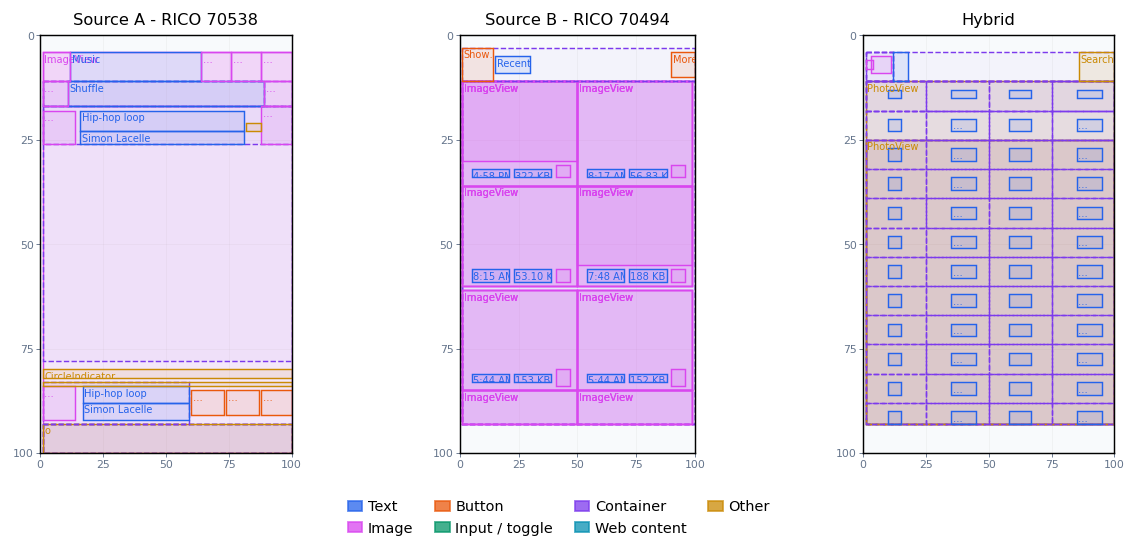

,panel,geometry
0,Source A,31 boxes; 0 non-drawable; 0 out-of-frame
1,Source B,51 boxes; 0 non-drawable; 0 out-of-frame
2,Hybrid,110 boxes; 1 non-drawable; 0 out-of-frame


### Source screenshots and repaired hybrid

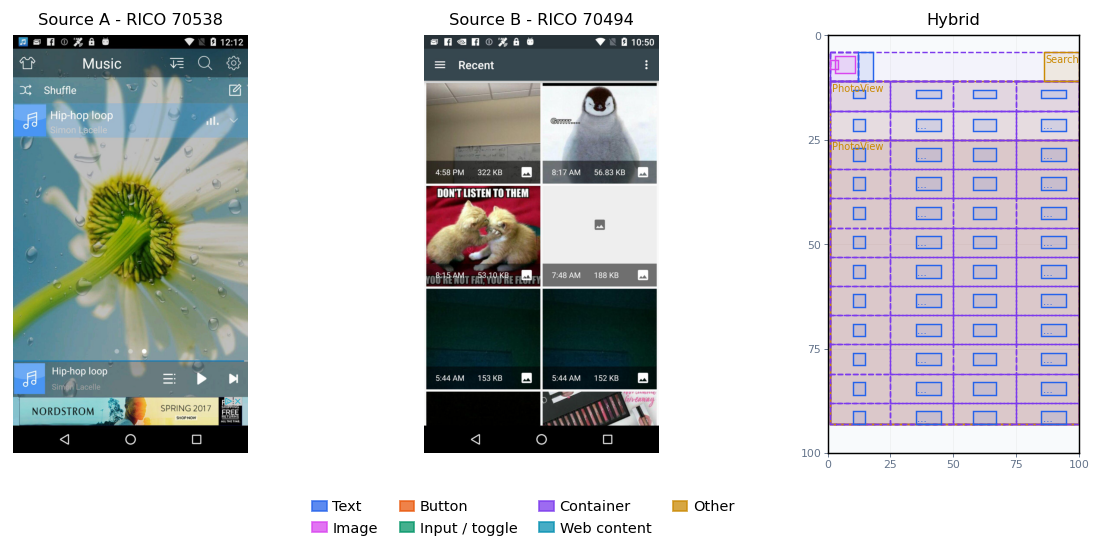

Saved both comparisons as PDF and PNG in C:\Users\Jonathan\Dev\screen2vec-revisited\graphics\hybrid_ui_reconstruction\70538_70494__qwen2.5-1.5b__4096_last__weighted_average_a0.55__20260907T115750787104Z


In [9]:
PALETTE = {
    "Text": "#2563eb", "Image": "#d946ef", "Button": "#ea580c",
    "Input / toggle": "#059669", "Container": "#7c3aed",
    "Web content": "#0891b2", "Other": "#ca8a04",
}

def element_type(node):
    name = str(node.get("class", "")).rsplit(".", 1)[-1].lower()
    if any(s in name for s in ("edittext", "checkbox", "switch", "radio", "seekbar", "spinner")):
        return "Input / toggle"
    if "button" in name:
        return "Button"
    if "image" in name:
        return "Image"
    if "text" in name:
        return "Text"
    if "webview" in name:
        return "Web content"
    if node.get("children") or any(s in name for s in ("layout", "toolbar", "list", "grid", "card")):
        return "Container"
    return "Other"

def drawable_components(screen):
    result = []
    for path, node in flatten_components(screen):
        if not isinstance(node, dict):
            continue
        bounds = node.get("bounds")
        if not isinstance(bounds, list) or len(bounds) != 4:
            continue
        if not all(isinstance(v, (int, float)) and not isinstance(v, bool)
                   and math.isfinite(v) for v in bounds):
            continue
        x1, y1, x2, y2 = bounds
        if x2 > x1 and y2 > y1:
            result.append((path, node, bounds))
    return result

def draw_wireframe(ax, screen, aspect, title):
    ax.set(xlim=(0, 100), ylim=(100, 0), title=title)
    ax.set_aspect(aspect)
    ax.set_facecolor("#f8fafc")
    ax.set_xticks([0, 25, 50, 75, 100])
    ax.set_yticks([0, 25, 50, 75, 100])
    ax.tick_params(labelsize=6, colors="#64748b", pad=1.5, length=2, width=0.5)
    ax.grid(alpha=0.15, linewidth=0.4)
    boxes = sorted(drawable_components(screen),
                   key=lambda item: (item[2][2]-item[2][0])*(item[2][3]-item[2][1]),
                   reverse=True)
    outside = 0
    for path, node, (x1, y1, x2, y2) in boxes:
        color = PALETTE[element_type(node)]
        container = bool(node.get("children"))
        outside += int(x1 < 0 or y1 < 0 or x2 > 100 or y2 > 100)
        rect = Rectangle(
            (x1, y1), x2-x1, y2-y1,
            facecolor=(*plt.matplotlib.colors.to_rgb(color), 0.035 if container else 0.10),
            edgecolor=color, linewidth=0.8, linestyle="--" if container else "-", zorder=2,
        )
        ax.add_patch(rect)
        if SHOW_LABELS and not container and x2-x1 >= 10 and y2-y1 >= 2:
            label = node.get("text") or node.get("content-desc") or str(node.get("class", "?")).rsplit(".", 1)[-1]
            label = textwrap.shorten(" ".join(str(label).split()),
                                     width=max(4, int((x2-x1)/2)), placeholder="…")
            artist = ax.text(x1+0.6, y1+0.5, label, fontsize=5.5,
                             va="top", color=color, clip_on=True, zorder=3)
            artist.set_clip_path(rect)
    if not boxes:
        ax.text(50, 50, "No drawable components", ha="center", va="center", fontsize=8)
    return f"{len(boxes)} boxes; {len(flatten_components(screen))-len(boxes)} non-drawable; {outside} out-of-frame"

def hybrid_display_aspect():
    if HYBRID_ASPECT == "source_a":
        return source_a["aspect"]
    if HYBRID_ASPECT == "source_b":
        return source_b["aspect"]
    if isinstance(HYBRID_ASPECT, (int, float)) and not isinstance(HYBRID_ASPECT, bool):
        if math.isfinite(HYBRID_ASPECT) and HYBRID_ASPECT > 0:
            return float(HYBRID_ASPECT)
    raise ValueError("HYBRID_ASPECT must be 'source_a', 'source_b', or a positive height/width.")

def comparison_figure(mode):
    if mode not in ("wireframes", "screenshots"):
        raise ValueError(mode)
    with plt.rc_context({"font.family": "DejaVu Sans", "figure.dpi": 130,
                         "axes.titlesize": 9, "axes.titlepad": 6}):
        fig, axes = plt.subplots(1, 3, figsize=(FIGURE_WIDTH_CM/2.54, FIGURE_HEIGHT_CM/2.54))
        notes = []
        for ax, label, source in zip(axes[:2], ("A", "B"), (source_a, source_b)):
            title = f"Source {label} - RICO {source['id']}"
            if mode == "wireframes":
                notes.append(draw_wireframe(ax, source["gt"], source["aspect"], title))
            else:
                ax.imshow(source["screenshot"])
                ax.set_title(title)
                ax.axis("off")
        notes.append(draw_wireframe(axes[2], hybrid_screen, hybrid_display_aspect(),
                                    "Hybrid"))
        #fig.suptitle(f"{MODEL_SLUG} | {embedding_name} | {operation_label}", fontsize=10, y=0.97)
        legend = [Patch(facecolor=color, edgecolor=color, alpha=0.75, label=name)
                  for name, color in PALETTE.items()]
        fig.legend(handles=legend, loc="lower center", ncol=4, frameon=False,
                   fontsize=8, bbox_to_anchor=(0.5, 0.015), handlelength=1,
                   handletextpad=0.4, columnspacing=1.5)
        fig.subplots_adjust(left=0.045, right=0.985, top=0.85, bottom=0.17, wspace=0.24)
        if run_dir is not None:
            for extension in ("pdf", "png"):
                fig.savefig(run_dir / f"{mode}.{extension}", dpi=200)
        plt.show()
        plt.close(fig)
    return notes

if hybrid_screen is None:
    raise ValueError("The repaired output is not a screen object. Inspect the saved raw text, "
                     "check the selected checkpoint, or increase MAX_NEW_TOKENS and rerun.")
display(Markdown("### Source wireframes and repaired hybrid"))
wireframe_notes = comparison_figure("wireframes")
display(pd.DataFrame({"panel": ["Source A", "Source B", "Hybrid"], "geometry": wireframe_notes}))
display(Markdown("### Source screenshots and repaired hybrid"))
comparison_figure("screenshots")
if run_dir:
    print("Saved both comparisons as PDF and PNG in", run_dir)

## 8. Inspect the generated hierarchy (optional)

`raw_prediction` is the exact decoded text. `repaired_prediction` / `hybrid_screen` contain the repaired object used in both figures. To try another mixture, change the configuration and Run All; the decoder cache is reused.

In [8]:
def component_table(screen):
    return pd.DataFrame([
        {"path": path, "class": node.get("class"), "text": node.get("text", ""),
         "content-desc": node.get("content-desc", ""), "bounds": node.get("bounds")}
        for path, node in flatten_components(screen) if isinstance(node, dict)
    ])

display(component_table(hybrid_screen))
# print(raw_prediction)
# print(json.dumps(repaired_prediction, ensure_ascii=False, indent=2))
# display(component_table(source_a["gt"]))
# display(component_table(source_b["gt"]))

,path,class,text,content-desc,bounds
0,/0,com.android.gallery3d.ui.GalleryProxyView,,,"[1, 11, 100, 93]"
1,/0/0,com.android.gallery3d.ui.PhotoProxyView,,,"[1, 11, 100, 93]"
2,/0/0/0,com.android.gallery3d.ui.PhotoView,,,"[1, 11, 100, 93]"
3,/1,com.android.internal.widget.ActionBarView,,,"[1, 4, 100, 11]"
4,/1/0,android.widget.LinearLayout,,"My Music, Navigate up","[1, 4, 12, 11]"
...,...,...,...,...,...
106,/46,com.android.internal.widget.ScrollingTabContai...,,,"[50, 88, 75, 93]"
107,/46/0,android.widget.TextView,Recent,,"[58, 90, 67, 93]"
108,/47,com.android.internal.widget.ScrollingTabContai...,,,"[75, 88, 100, 93]"
109,/47/0,android.widget.TextView,Library,,"[85, 90, 95, 93]"
